In [20]:
import pade_utils as pdu
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
from scipy.optimize import linear_sum_assignment
from scipy.linalg import eig, svd
from numpy.lib.stride_tricks import sliding_window_view

tmax = 1000
delta_t = 0.01
time = np.linspace(0, tmax * delta_t, tmax)

In [13]:
def signal_to_poles_and_zeros(signal, datapoints, order):
    """
    A function that takes our signal (FID) and works through the linear algebra, to the point until we have determined the numerator P(w) and denominator Q(w).
    It returns the poles and zeros so we can do calculations wiht Froissart doubles.
    """
    
    # Get Q(w) coefficients
    signal_used = signal[:datapoints].tolist()
    empty_matrix = []
    rhs_vector = []

    for i in range(datapoints - order):
        matrix_row = signal_used[i:order+i]
        matrix_row.reverse()
        empty_matrix.append(matrix_row)
        rhs_vector.append( -1 * signal_used[order+i])

    matrix = np.array(empty_matrix, dtype=complex)
    rhs_vector = np.array(rhs_vector, dtype=complex)

    scales = np.linalg.norm(matrix, axis = 0)
    matrix_scaled = matrix / scales

    q_k_scaled, _, _, _ = np.linalg.lstsq(matrix_scaled, rhs_vector, rcond=None)
    q_k = q_k_scaled / scales

    # Get P(w) coefficients
    q_ascending = np.append(1, q_k)

    p_k = []

    for n in range(order):
        coefficient = 0

        for j in range(n + 1):
            coefficient += q_ascending[j] * signal_used[n - j]

        p_k.append(coefficient)

    p_k_coefficients = np.array(p_k[::-1], dtype=complex)
    q_k_coefficients = np.array(q_ascending[::-1], dtype=complex)

    import mpmath as mp

    mp.mp.dps = 80

    coeffs_mp = [mp.mpc(float(c.real), float(c.imag))for c in p_k_coefficients]
    zeros_precise = mp.polyroots(coeffs_mp, maxsteps=500, extraprec=100)

    coeffs_mp = [mp.mpc(float(c.real), float(c.imag))for c in q_k_coefficients]
    poles_precise = mp.polyroots(coeffs_mp, maxsteps=500, extraprec=100)

    return poles_precise, zeros_precise

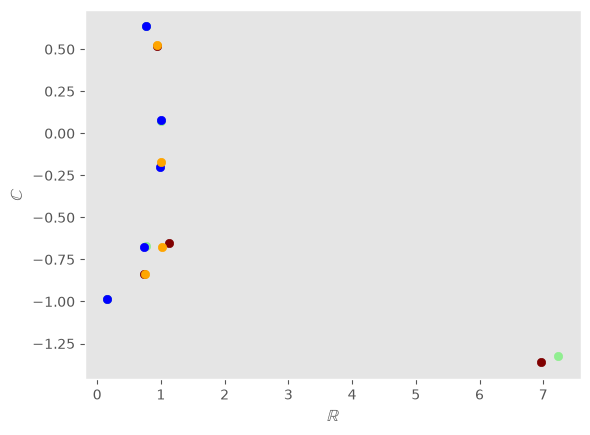

In [14]:
order = 10

noisy_signal = pdu.generate_synthetic_signal(order = 5, noise_level = 1e-2)
true_signal = pdu.generate_synthetic_signal(order = 5, noise_level = 0)
        
poles, zeros = signal_to_poles_and_zeros(noisy_signal, datapoints= 50, order = 5)
poles = np.array(poles, dtype=np.complex128)
zeros = np.array(zeros, dtype=np.complex128)


true_poles, true_zeros = signal_to_poles_and_zeros(true_signal, datapoints= 50, order = 5)
true_poles = np.array(true_poles, dtype=np.complex128)
true_zeros = np.array(true_zeros, dtype=np.complex128)

plt.scatter(poles.real, poles.imag, color='lightgreen')
plt.scatter(zeros.real, zeros.imag, color='maroon')

plt.scatter(true_poles.real, true_poles.imag, color='blue')
plt.scatter(true_zeros.real, true_zeros.imag, color='orange')


plt.xlabel("$\\mathbb{R}$")
plt.ylabel("$\\mathbb{C}$")

plt.grid()

plt.show()

When we add even a small amount of noise, the poles and residues move massively. This is a huge problem. The problem is the sensitivity of root finding. Even a tiny amount of added noise (on the order of 1 part in a million) massively shifts where the poles end up. This isn't a problem of how precisely the root values are stored (here we have used mpmath for arbitrary precision), but rather a genuine problem in root finding. We can still use Pade to reconstruct signals and for phase correction, but our current method won't be enough. We need a better method of de-noising the matrices.

# Matrix Pencil and Generalized Eigenvalues

From our introduction, we will recall that our generating function for the sequence is $$\mathcal{G}(w) = \sum_{k=1}^N \frac{d_k}{1 - \mathcal{z}_k w}$$ From this we can recover the signal $$\mathcal{S} = \sum_{k = 1}^{N} d_k \mathcal{z}_k^n$$

First, we imagine our signal has the following sampled points: $$\mathcal{s}_0, \mathcal{s}_1, \mathcal{s}_2, ..., \mathcal{s}_{M-1}$$

For simplicity we will assume we have $N$ resonances and $2N$ datapoints. 

We construct from these two **Hankel Matrices**, a special class of matrix with constant entries along it's *anti-* diagonal called $H_0$ and $H_1$, where:



$$H_0 = \begin{pmatrix} 
  s_0 & s_1 & ... & s_{N-1} \\
  s_1 & s_2 & ... & s_N \\
  ... & ... & ... & ... \\
  s_{N-1} & s_N & ... & s_{2N-2} 
\end{pmatrix} \hspace{25mm} H_1 = \begin{pmatrix} 
  s_1 & s_2 & ... & s_{N} \\
  s_2 & s_3 & ... & s_{N+1} \\
  ... & ... & ... & ... \\
  s_{N} & s_{N+1} & ... & s_{2N-1} 
\end{pmatrix}$$

Such that $H_1$ is simply $H_0$ but shifted by one time step. But why do this? Consider just one resonance $s_n = dz^n$ and its immediate successor $s_{n+1} = dz^{n+1} = zs^n$. Using these matrices we can exploit this property! We know that $H_1$ is simply $H_0$ with each signal point multiplied by its resonance $z$. For one resoannce this is then simple, we jsut compare the matrices, we know there is a factor of $z$, and so we find our resonance. But for multiple resoannces, each resonance is multiplied by it's own $z$, so we can no longer have $H_1 = zH_0$ for any single $z$. We have to write out a more complex matrix equation. Imagine we could find some vector **v** such that $H_1 v = \lambda H_0 v$, then this would have exactly the same property as our single resonances, where advancing forward a time-step is the same as some scalar multiplcation. This vector would represent a single resoannce, whilst $\lambda$ would show it's evolution in time. We can show this explicitly by defining our Matrix Pencil.

This is what we will ultimately exploit, but to make full use of this we need to define yet more matrices. 

We define the Vandermonde Matrix: 

$$V = \begin{pmatrix} 
1 & 1 & ... & 1 \\
z_1 & z_2 & ... & z_N \\
z_1^2 & z_2^2 & ... & z_N^{2} \\
... & ... & ... & ... \\
z_{1}^{N-1} & z_2^{N-1} & ... & z_N^{N-1}
\end{pmatrix}$$

Alongside two diagonal matrices: $$D = \mathrm{diag} [d_1, d_2, ..., d_N]$$ $$Z = \mathrm{diag} [z_1, z_2, ..., z_N]$$

With these, we can show that: $$H_0 = VDV^T \hspace{20mm} H_1 = VDZV^T$$

This is not difficult to verify, but the maths is not interesting. It is not suprising that multiplying through by the z-values gets us from one matrix to the other. 

Let us define the **Matrix Pencil** $$H_1 - \lambda H_0$$ Where $\lambda$ is some scalar variable. For finding our vector **v**, it is equivalent to asking what non-zero solutions exist to: $$(H_1 - \lambda H_0) v=0$$ From linear algebra, we can show that the solution to this occurs when our matrix is singular $$\mathrm{det}[(H_1 - \lambda H_0)] = 0$$ Substituting in our expressions for $H_0$ and $H_1$ and using the product rules for determinants, we find that this is equivalent to finding: $$\mathrm{det}(V)^2 \mathrm{det}(D) \mathrm{det}(Z - \lambda I) = 0$$

As $V$ and $D$ can be assumed non-zero, this occurs when $Z - \lambda I = 0$. As $Z$ is diagonal, we find that $\lambda_k = z_k$. The generalised eigenvalues of our matrix pencil are the resonances, from which (as we have done previously) we can obtain our other parameters. This method lets us avoid the sensitivity we found in root finding, though this does not eliminate the role of noise and can still be wrong when the matrix is poorly conditioned our resonances are very close, etc. Let's try and build our matrix pencil solver and see how well it does on an (initially) clean signal.

In [15]:
clean_signal = pdu.generate_synthetic_signal(order = 5, noise_level = 0)    

def Hankel(signal, order, n_datapoints = 200):
    """
    Takes in the signal, alongside the order (how many resonances we'd like to decompose into) and constructs the two Hankel matrices.
    """

    sgnl = signal[: n_datapoints]
    H_0 = []
    H_1 = []

    for r in range(order):
        row_H0 = []
        row_H1 = []
        
        for c in range(order):
            row_H0.append(sgnl[r+c])
            row_H1.append(sgnl[r+c+1])

        H_0.append(row_H0)
        H_1.append(row_H1)

    return np.array(H_0), np.array(H_1)

Now we want to solve the eigenvalue problem. There are a lot of sophisticated, very fast methods for finding eigenvalues, as it is such an important part of linear algebra. Because of this, we will use scipy's eig library in order to test our matrices. Though we have changed the root finding method for the z_ks, the step to attaining the d_ks remains the same; we construc thte Vandermonde matrix and solve as we have done several times before.

In [16]:
H_0, H_1 = Hankel(clean_signal, order=5)
z_k = eig(H_1, H_0)[0]

def get_dk(signal, z):
    """
    From the signal and the z_k we generate the linear equations for the d_k
    """

    empty_matrix = []
    rhs_vector = []

    for i in range(len(z)):
        matrix_row = [z**i for z in z]
        empty_matrix.append(matrix_row)
        rhs_vector.append(signal[i])

    matrix = np.array(empty_matrix, dtype=complex)
    rhs_vector = np.array(rhs_vector, dtype=complex)

    d_k = np.linalg.solve(matrix, rhs_vector)
    
    return d_k  

d_k = get_dk(clean_signal, z_k)

In [17]:
def reconstruct_signals(z_k, d_k, T= 1000):
    """
    Using our acquired z_k and d_k values, we obtain the paramters for each exponential and reconstruct the full signal
    """

    assert len(z_k) == len(d_k)

    individual_signals = []

    for z, d in zip(z_k, d_k):

        signal = []

        for n in range(T):
            signal.append(d * z**n)

        individual_signals.append(signal)

    individual_signals = np.array(individual_signals, dtype=complex)
    reconstructed_fid = np.sum(individual_signals, axis=0)

    return individual_signals, reconstructed_fid  

Maximum error: 1.045e-10


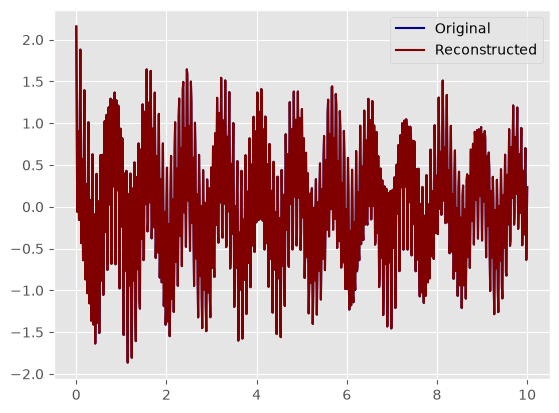

In [23]:
individual_signals, reconstructed_fid = reconstruct_signals(z_k, d_k)

error = np.max(np.abs(clean_signal[:len(reconstructed_fid)] - reconstructed_fid))
print(f"Maximum error: {error:.3e}")



plt.style.use('ggplot')
plt.plot(time, np.real(clean_signal)[:1000], label="Original", zorder =1, color='darkblue')
plt.plot(time, np.real(reconstructed_fid)[:1000], label="Reconstructed", zorder =2, color='maroon')
plt.legend()
plt.show()

OK! So it works for a small number of signals with no noise. This is excellent but- as with our root finding, we would like to add the ability to overdetermine the number of points we use, and see how it deals with lots of closely spaced resonances, and then onto noisy spectra. We want to separate out the number of datapoints we use from the order. This is not a trivial thing to do, as it was with our previous approach, because the number of datapoints is related to the stability of the matrix. If we, with our current implementation, try to see how it deals with 20 resonances, for instance, we get an error:

In [24]:
busy_signal = pdu.generate_synthetic_signal(order = 20, noise_level = 0)

H_0, H_1 = Hankel(clean_signal, order=20)
z_k = eig(H_1, H_0)[0]
d_k = get_dk(busy_signal, z_k)

/tmp/ipykernel_149696/436113976.py:13: RuntimeWarning: invalid value encountered in scalar power
  matrix_row = [z**i for z in z]


In [25]:
print("Infinite eigenvalues:", np.sum(np.isinf(z_k)))

Infinite eigenvalues: 15


We get this error because some of our eigenvalues are infinite!! As we seem to run into often, the difficulty dealing with closely spaced resonances here arises from floating point data. When resonances are very close, and floating point precision begins to play a role, the vectors **v** for any two resonances can become almost identical. The columns of the Vandermonde Matrix become linearly dependent, which causes $H_0$ to become singular, leading to infinite eigenvalues. To prevent this, we need to use SVD truncation in order to enforce the number of datapoints and the order, separately. SVD is detailed in notebook 2, but has been copied here for convenience.

**Singular Vector Decomposition (SVD)** is a very powerful tool, and one that can be used in multiple ways in order to better solve the matrix problems $Aq = b$. We will discuss two approaches here: the truncated SVD, and the null vector approach. Both of these can be very powerful, and will help not jsut in busy systems, but evena s we begin to see how noise affects busy spectra. Let us detail the truncated SVD approach first.

Any normal, square matrix, with an orthonormal eigenbasis, can be decomposed into a canonical form given by $$A = Q^{-1}DQ$$ Where $D$ is a diagonal matrix. An SVD generalises this to any $m \times n$ matrix. Geometrically, it is equivalent to saying the effect of any matrix on a basis, is equivalent to a rotation, followed by a scaling, followed by another rotation. Specifically, any matrix $\textbf{M}$ can be decomposed into: $$\textbf{M} = \textbf{U}  \Sigma  \textbf{V}^*$$

Where $\textbf{V}^*$ is a rotation, $\Sigma$ is a scaling, and **U** a second rotation. It is widely used across many areas of mathematics, but what is initially important is looking at the diagonal scaling matrix $\Sigma$. This is an $n \times n$ diagonal matrix composed of $n$ singular values, $\sigma$, which tells us how important a given direction is for the matrix, where tiny values correspond to a relatively small impact. When we solve $Aq = b$, we are really trying to solve $$q = A^{-1}b$$ Where $A^{-1}$ represents the pseudo-inverse. And using our SVD to decompose A this gives:
$$q = V \Sigma^{-1} U^* b$$

But taking $\Sigma^{-1}$ for a square diagonal matrix is equivalent to simply inverting the eignevalues. Each $\sigma_n \rightarrow \frac{1}{\sigma_n}$ means that these tiny amplitudes get amplified massively. Truncating the SVD refers to discarding these tiny values, where floating point errors will have an outsized impact, and can be a very powerful tool for helping to resolve busier/ noisier systems. 

Let's add this truncated SVD into our solver, and see how it impacts numerical stability.

In [26]:
def matrix_pencil(signal, order, n_datapoints=200):

    signal = np.asarray(signal, dtype=complex)[:n_datapoints]
    M = len(signal)

    if M < 2 * order:
        raise ValueError("Not enough samples for the requested order.")

    L = M // 2

    windows = sliding_window_view(signal, L)

    H_0 = windows[:-1]
    H_1 = windows[1:]

    U, S, Vh = svd(H_0, full_matrices=False)

    U_N = U[:, :order]
    S_N = S[:order]
    V_N = Vh[:order, :].conj().T

    B = U_N.conj().T @ H_1 @ V_N

    z_k = eig(B, np.diag(S_N))[0]
    
    z_k = z_k / np.maximum(1, np.abs(z_k)) # Prevents exponential graph if z > 1

    
    n = np.arange(M)

    V = z_k[None, :] ** n[:, None]
    d_k = np.linalg.lstsq(V, signal, rcond=None)[0]

    return z_k, d_k, S

Let's try this on our busy signal:

Maximum reconstruction error: 7.254e-12
Largest eigenvalue magnitude: 0.999860


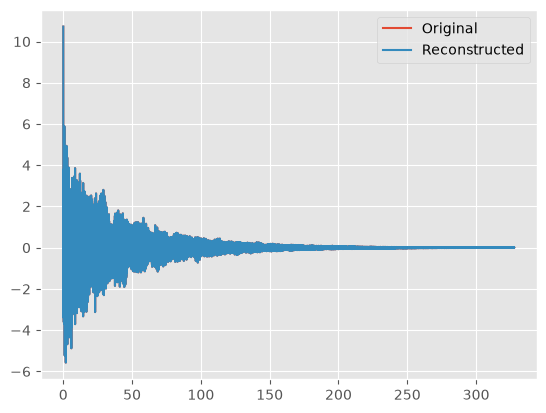

In [27]:
busy_signal = pdu.generate_synthetic_signal(order = 20, noise_level = 0)
z_k, d_k, singular_values = matrix_pencil(busy_signal, order=20, n_datapoints=800)

n = np.arange(len(clean_signal))

reconstructed_fid = (z_k[None, :] ** n[:, None]) @ d_k

error = np.max(np.abs(busy_signal - reconstructed_fid))

print(f"Maximum reconstruction error: {error:.3e}")
print(f"Largest eigenvalue magnitude: {np.max(np.abs(z_k)):.6f}")

time = np.arange(len(busy_signal)) * 0.01

plt.plot(time, busy_signal.real, label="Original")
plt.plot(time, reconstructed_fid.real, label="Reconstructed")

plt.legend()
plt.show()

SVD performs double duty here as it not only plays a role in ensuring numerical stability, but also acts as a filter for noise. Let's add some noise to this signal, but force it to still only reconstruct with 20 resonances.

Maximum reconstruction error: 2.143e-01
Largest eigenvalue magnitude: 0.999803


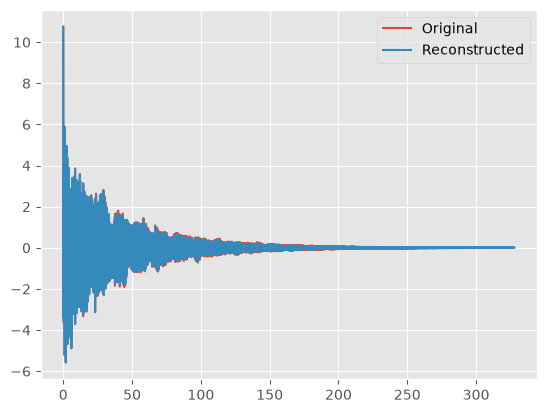

In [28]:
clean_signal = pdu.generate_synthetic_signal(order = 20, noise_level = 0, seed=18)
noisy_signal = pdu.generate_synthetic_signal(order = 20, noise_level = 0.1, seed=18)

z_k, d_k, singular_values = matrix_pencil(noisy_signal, order=20, n_datapoints=800)

n = np.arange(len(noisy_signal))

reconstructed_fid = (z_k[None, :] ** n[:, None]) @ d_k

error = np.max(np.abs(clean_signal - reconstructed_fid))

print(f"Maximum reconstruction error: {error:.3e}")
print(f"Largest eigenvalue magnitude: {np.max(np.abs(z_k)):.6f}")

time = np.arange(len(busy_signal)) * 0.01

plt.plot(time, clean_signal.real, label="Original")
#plt.plot(time, noisy_signal.real, label="Noisy")
plt.plot(time, reconstructed_fid.real, label="Reconstructed")

plt.legend()
plt.show()

OK! This does a decent job at filtering out noise and reconstruct the initial resonances. There are multiple improvements and more filters we can add here, but this may be more than sufficient for our phase estimation purposes.